# Lab 3: LSTM Forecasting of Monthly Precipitation (Honolulu Airport, Hawaii, 1940 to 2024)

Forecasts next month precipitation from the previous 12 months with a stacked LSTM in
PyTorch, using a chronological train/test split so the model never sees the future.

**Data:** NOAA National Centers for Environmental Information monthly precipitation for
Honolulu Airport, June 1940 to February 2024 (1,005 months). The file has four header lines,
then `Date` (YYYYMM), `Value` (inches) and `Anomaly`; `-99` marks a missing month.

**Run in Google Colab.** Upload `HW_precipitation_1939_2024.csv` and run all cells.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DATA_PATH = "HW_precipitation_1939_2024.csv"
WINDOW = 12

1005 months, 8 missing months filled by interpolation


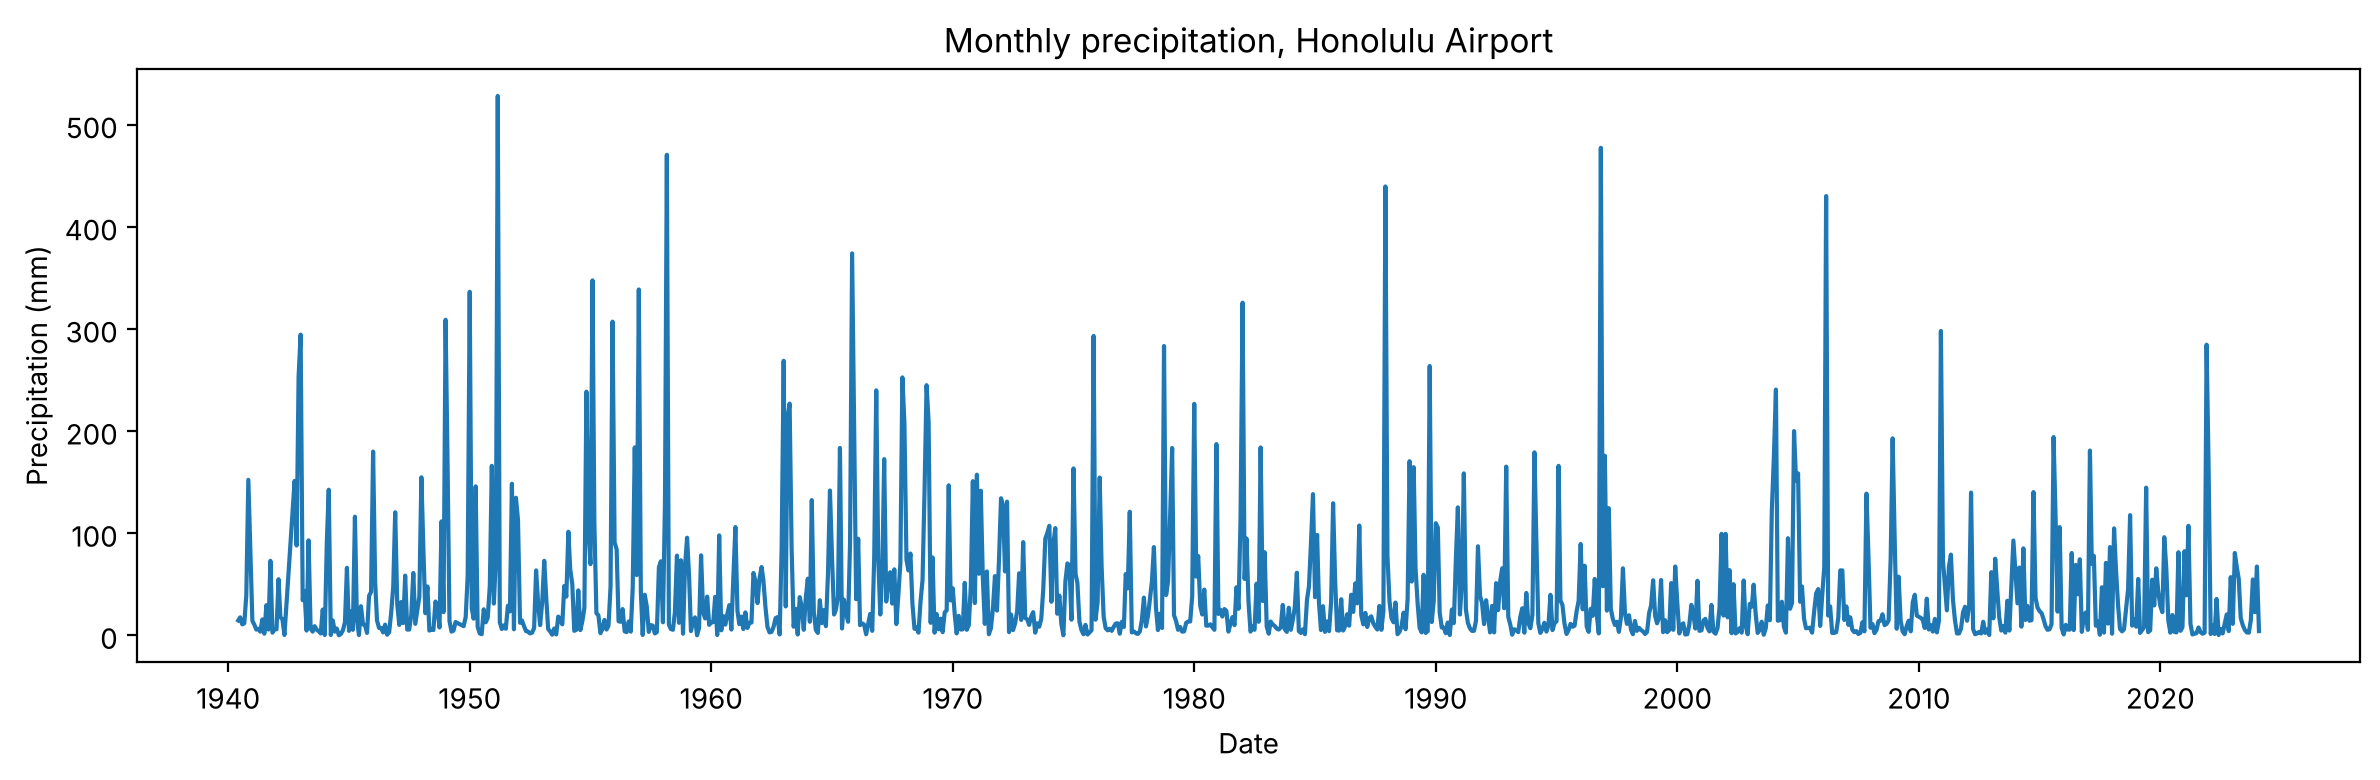

In [2]:
data = pd.read_csv(DATA_PATH, skiprows=4)        # first four lines are NOAA header text
data["Date"] = pd.to_datetime(data["Date"].astype(str), format="%Y%m")
data = data.sort_values("Date").reset_index(drop=True)

# -99 marks a missing month; convert inches to mm, then fill the few gaps by linear interpolation
data["Precipitation"] = data["Value"].replace(-99, np.nan) * 25.4
print(f"{len(data)} months, {data['Precipitation'].isna().sum()} missing months filled by interpolation")
data["Precipitation"] = data["Precipitation"].interpolate()

plt.figure(figsize=(12, 4))
plt.plot(data["Date"], data["Precipitation"])
plt.title("Monthly precipitation, Honolulu Airport"); plt.xlabel("Date"); plt.ylabel("Precipitation (mm)")
plt.tight_layout(); plt.show()

## Build sequences: 12 months in, next month out

In [3]:
values = data["Precipitation"].values.astype("float32").reshape(-1, 1)

split = int(len(values) * 0.8)                 # chronological split
scaler = MinMaxScaler().fit(values[:split])    # fit on the training period only
scaled = scaler.transform(values).astype("float32")

def make_sequences(series, window):
    X, y = [], []
    for i in range(len(series) - window):
        X.append(series[i:i + window])
        y.append(series[i + window])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, WINDOW)          # X: (n, 12, 1), y: (n, 1)
n_train = split - WINDOW
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]
test_dates = data["Date"].values[WINDOW + n_train:]
print(X_train.shape, X_test.shape)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)), batch_size=64, shuffle=False)

(792, 12, 1) (201, 12, 1)


## Model

In [4]:
class TimeSeriesLSTM(nn.Module):
    def __init__(self, hidden=40, layers=3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True)
        self.linear = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.linear(out[:, -1, :])      # prediction from the last time step

model = TimeSeriesLSTM()
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [5]:
history = []
for epoch in range(100):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        test_loss = np.mean([criterion(model(xb), yb).item() for xb, yb in test_loader])
    history.append(test_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}: test MAE (scaled) {test_loss:.4f}")

Epoch 10: test MAE (scaled) 0.0511


Epoch 20: test MAE (scaled) 0.0470


Epoch 30: test MAE (scaled) 0.0474


Epoch 40: test MAE (scaled) 0.0466


Epoch 50: test MAE (scaled) 0.0472


Epoch 60: test MAE (scaled) 0.0460


Epoch 70: test MAE (scaled) 0.0463


Epoch 80: test MAE (scaled) 0.0472


Epoch 90: test MAE (scaled) 0.0465


Epoch 100: test MAE (scaled) 0.0461


## Evaluate in millimetres

LSTM test MAE: 26.8 mm
Seasonal median baseline MAE: 27.5 mm
Naive (same as last month) baseline MAE: 37.5 mm


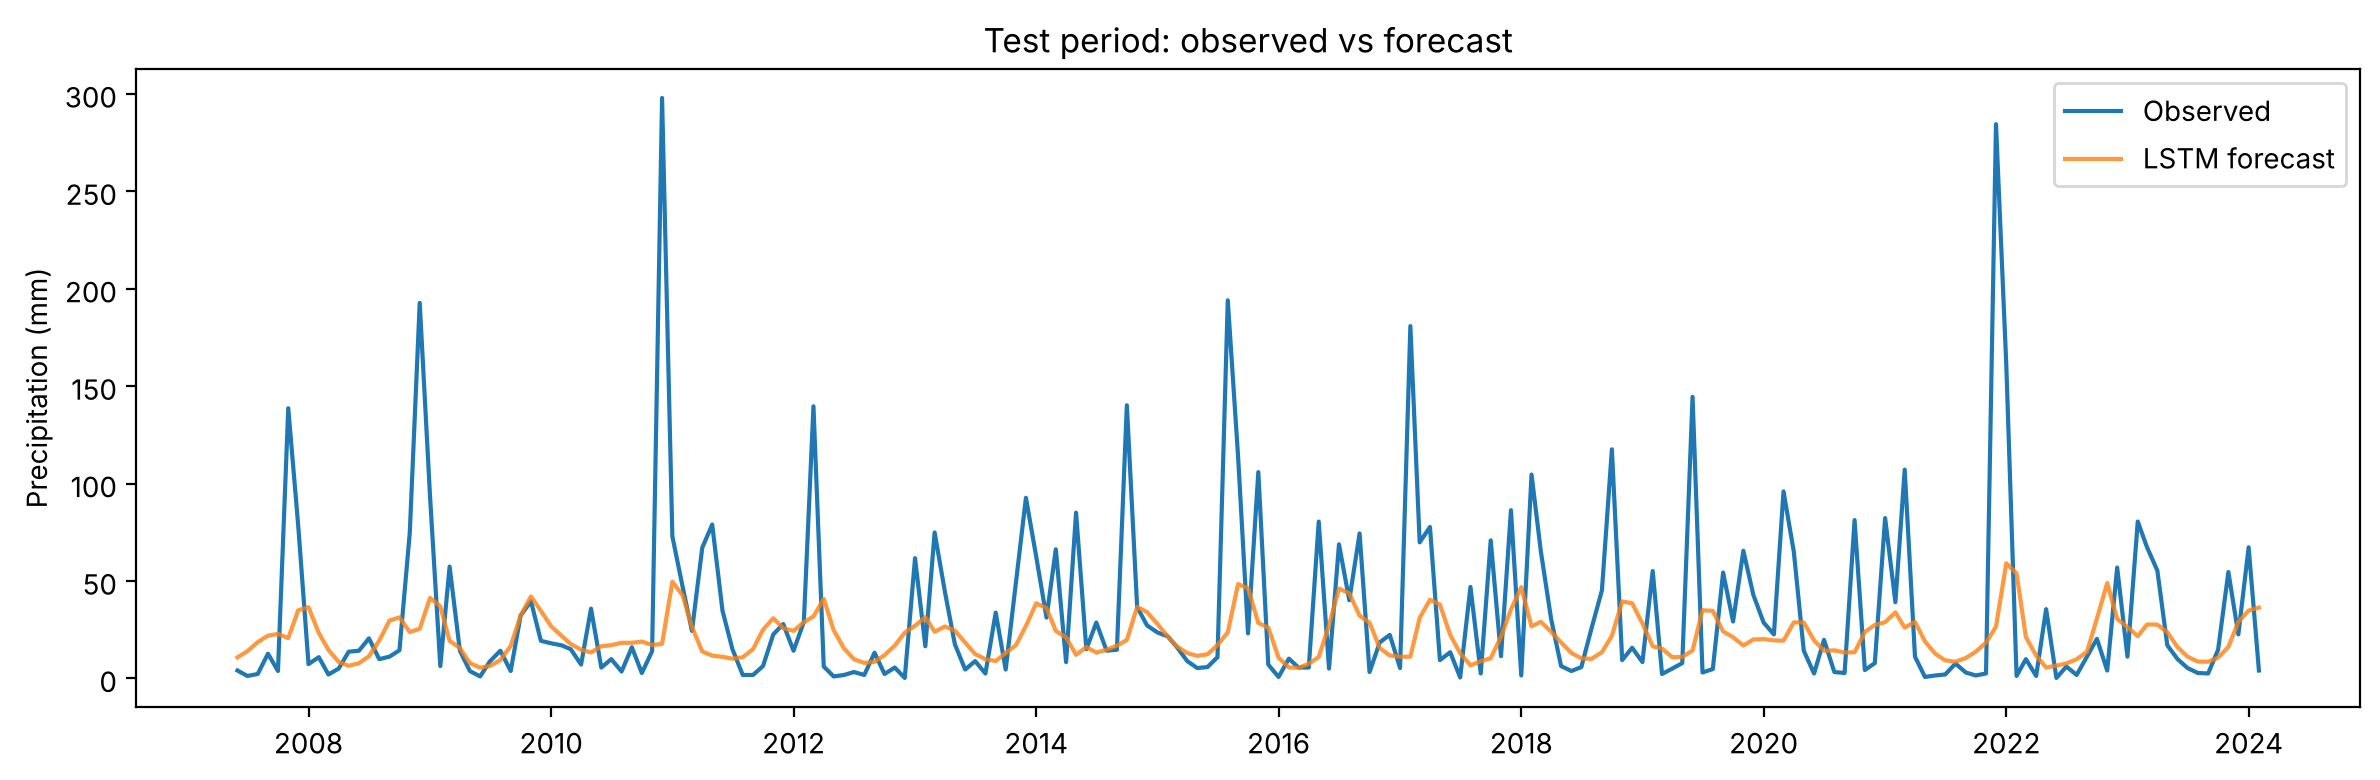

In [6]:
model.eval()
with torch.no_grad():
    preds_scaled = model(torch.tensor(X_test)).numpy()
preds = scaler.inverse_transform(preds_scaled).ravel()
truth = scaler.inverse_transform(y_test).ravel()
mae_mm = np.mean(np.abs(preds - truth))
naive_mae = np.mean(np.abs(truth[1:] - truth[:-1]))   # baseline: next month equals this month

# Seasonal baseline: the median for each calendar month, from the training years only
train_months = data["Date"].dt.month.values[:split]
monthly_median = pd.Series(values[:split].ravel()).groupby(train_months).median()
seasonal_pred = monthly_median.loc[data["Date"].dt.month.values[split:]].values
seasonal_mae = np.mean(np.abs(seasonal_pred - truth))

print(f"LSTM test MAE: {mae_mm:.1f} mm")
print(f"Seasonal median baseline MAE: {seasonal_mae:.1f} mm")
print(f"Naive (same as last month) baseline MAE: {naive_mae:.1f} mm")

plt.figure(figsize=(12, 4))
plt.plot(test_dates, truth, label="Observed")
plt.plot(test_dates, preds, label="LSTM forecast", alpha=0.8)
plt.title("Test period: observed vs forecast"); plt.ylabel("Precipitation (mm)")
plt.legend(); plt.tight_layout(); plt.show()